# 01 · Data cleaning

**Goal:** turn the raw Online Retail II export into two clean, customer-level tables
that every later phase (RFM, segmentation, CLV, churn) can rely on:

- `transactions.parquet`: one row per purchased item line, attributable to a known customer
- `returns.parquet`: return lines that could not be paired with the purchase they undo

The raw data has several problems: the two yearly sheets overlap, some rows are duplicated,
almost a quarter of the lines have no customer, and the files mix real products with
postage, fees and accounting adjustments. Returns are recorded as separate invoices with
negative quantities. Each step below handles one of these issues, explains why, and
logs how many rows, customers and how much revenue it removes.

**About the business:** a UK-based online retailer of giftware. Many customers are
wholesalers, which explains some very large orders.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src import cleaning

RAW_FILE = PROJECT_ROOT / "data" / "raw" / "online_retail_II.xlsx"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

## Load the raw data

The Excel file has one sheet per year. Reading it takes a minute or two.

In [2]:
sheets = cleaning.load_sheets(RAW_FILE)

for name, sheet in sheets.items():
    print(f"{name}: {len(sheet):,} rows, "
          f"{sheet['InvoiceDate'].min()} -> {sheet['InvoiceDate'].max()}")

sheets["Year 2009-2010"].head()

Year 2009-2010: 525,461 rows, 2009-12-01 07:45:00 -> 2010-12-09 20:01:00
Year 2010-2011: 541,910 rows, 2010-12-01 08:26:00 -> 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


A cleaning log tracks the effect of every step. Revenue here is simply `quantity × price`
summed over all lines, so returns (negative quantities) already reduce it.

In [3]:
log = []

def record(step, df):
    """Append the state of the data after a cleaning step to the log."""
    log.append({
        "step": step,
        "rows": len(df),
        "invoices": df["invoice"].nunique(),
        "customers": df["customer_id"].nunique(),
        "net_revenue": (df["quantity"] * df["price"]).sum(),
    })

raw = pd.concat(sheets.values(), ignore_index=True).rename(columns=cleaning.COLUMN_NAMES)
record("Raw data (both sheets)", raw)

## Step 1 · Remove the overlap between the two sheets

The first sheet ends on 2010-12-09 but the second one starts on 2010-12-01, so nine days
appear twice. Before dropping anything, check that those rows really are identical copies
and not, say, a corrected re-export.

In [4]:
first, second = sheets["Year 2009-2010"], sheets["Year 2010-2011"]
overlap_first = first[first["InvoiceDate"] >= second["InvoiceDate"].min()]
overlap_second = second[second["InvoiceDate"] <= first["InvoiceDate"].max()]

comparison = overlap_first.merge(overlap_second.drop_duplicates(), how="outer", indicator=True)
print(f"Overlap rows: {len(overlap_first):,} in sheet 1, {len(overlap_second):,} in sheet 2")
comparison["_merge"].value_counts()

Overlap rows: 22,523 in sheet 1, 22,523 in sheet 2


_merge
both          22523
left_only         0
right_only        0
Name: count, dtype: int64

Every overlapping row exists in both sheets, and nothing is present in only one of them.
The overlap is a pure double export, so those days are kept from the first sheet only.

This is done as its own step rather than with a global `drop_duplicates()`, because it is a
different problem from duplicated rows inside a sheet (next step) and deserves its own count.

In [5]:
df = cleaning.combine_sheets(sheets)
record("1. Remove sheet overlap", df)
print(f"{len(raw) - len(df):,} rows removed")

22,523 rows removed


## Step 2 · Remove exact duplicate rows

Some rows are identical in every column: same invoice, product, quantity, price and minute.

In [6]:
dup_mask = df.duplicated(keep=False)
print(f"{df.duplicated().sum():,} duplicated rows ({df.duplicated().mean():.1%})")
df[dup_mask].sort_values(["invoice", "stock_code"]).head(6)

11,812 duplicated rows (1.1%)


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


A real order would normally record the same product once with the total quantity, so a line
repeated with identical values is most likely a double scan or a system glitch.
This is an **assumption**: the data cannot prove it, but the effect is small (about 1% of rows)
and keeping them would inflate quantities and revenue for those invoices.

In [7]:
df = cleaning.drop_exact_duplicates(df)
record("2. Drop exact duplicates", df)

## Step 3 · Remove lines without a customer ID

Every later phase works at customer level, so a line that cannot be attributed to a customer
is of no use there. It is worth checking how much is lost and whether it looks random.

In [8]:
missing = df["customer_id"].isna()
line_revenue = df["quantity"] * df["price"]
positive = line_revenue > 0

print(f"Lines without customer: {missing.mean():.1%}")
print(f"Share of positive revenue without customer: "
      f"{line_revenue[positive & missing].sum() / line_revenue[positive].sum():.1%}")

# Does a single invoice ever mix lines with and without a customer?
mixed = df.groupby("invoice")["customer_id"].agg(lambda s: s.isna().any() and s.notna().any())
print(f"Invoices mixing known and missing customers: {mixed.sum()}")

Lines without customer: 22.8%
Share of positive revenue without customer: 15.1%


Invoices mixing known and missing customers: 0


Missing IDs are an invoice-level property: an invoice either has a customer or it does not.
This points to orders placed without a registered account (or recorded by a different system),
not to random gaps in otherwise known orders.

There is no reliable way to impute an identity, so these lines are dropped.
The consequence must be stated clearly: **all customer metrics in this project describe
registered customers, who generate about 85% of the revenue**.

In [9]:
df = cleaning.drop_missing_customers(df)
record("3. Drop missing customer ID", df)

## Step 4 · Remove non-positive prices

In [10]:
print(f"Price = 0: {(df['price'] == 0).sum():,} lines, price < 0: {(df['price'] < 0).sum():,} lines")
df.loc[df["price"] == 0, "description"].value_counts().head(8)

Price = 0: 70 lines, price < 0: 0 lines


description
Manual                            7
CHRISTMAS PUDDING TRINKET POT     2
This is a test product.           2
REGENCY CAKESTAND 3 TIER          2
6 RIBBONS EMPIRE                  1
DOOR MAT FAIRY CAKE               1
CHRISTMAS CRAFT WHITE FAIRY       1
ANTIQUE LILY FAIRY LIGHTS         1
Name: count, dtype: int64

Zero-price lines are free items, manual entries and a test product. They carry no information
on spending and would make the average order value meaningless. Negative prices
("Adjust bad debt") belong to lines without a customer and were already removed in step 3,
but the filter covers them anyway.

In [11]:
df = cleaning.drop_non_positive_prices(df)
record("4. Drop non-positive prices", df)

## Step 5 · Remove stock codes that are not products

Normal product codes start with five digits (e.g. `85123A`). Codes that do not follow this
pattern need a look one by one.

In [12]:
non_standard = df[~df["stock_code"].str.match(r"^\d{5}")]
(non_standard
 .assign(revenue=non_standard["quantity"] * non_standard["price"])
 .groupby("stock_code")
 .agg(lines=("invoice", "size"), description=("description", "first"), revenue=("revenue", "sum"))
 .sort_values("lines", ascending=False)
 .head(20))

,lines,description,revenue
stock_code,,,
POST,1983,POSTAGE,110338.510
M,1078,Manual,-185701.190
C2,254,CARRIAGE,12271.000
D,170,Discount,-12785.340
ADJUST,61,Adjustment by john on 26/01/2010 16,2038.120
BANK CHARGES,37,Bank Charges,330.001
PADS,18,PADS TO MATCH ALL CUSHIONS,-36.583
DOT,16,DOTCOM POSTAGE,11906.360
CRUK,16,CRUK Commission,-7933.430


Almost all of these are not merchandise: postage (`POST`, `DOT`, `C2`), manual entries (`M`),
discounts (`D`), accounting adjustments, bank charges, a charity commission (`CRUK`) and test
items. Including them would distort what a customer spends on products: postage is a
pass-through cost and manual entries are mostly large credits (about -£186k in total).
`PADS` and `SP1002` are real products with an unusual code, so they stay.

The full list in `NON_PRODUCT_CODES` (`src/cleaning.py`) also covers codes seen in the raw data
only on lines without a customer (Amazon fees, samples, gift vouchers), so the filter still works
if the order of the steps changes.

In [13]:
df = cleaning.drop_non_products(df)
record("5. Drop non-product codes", df)

## Step 6 · Separate purchases from returns

Cancelled invoices start with `C` and have negative quantities. At this point every
negative quantity should belong to a `C` invoice: the stock write-offs ("damaged",
"thrown away") had no customer and were removed in step 3. Lines where sign and invoice
type disagree are counted before they are dropped.

In [14]:
is_c = df["invoice"].str.startswith("C")
print(f"C invoices with positive quantity: {(is_c & (df['quantity'] > 0)).sum()}")
print(f"Normal invoices with negative quantity: {(~is_c & (df['quantity'] < 0)).sum()}")

purchases, returns = cleaning.split_purchases_returns(df)
print(f"Purchases: {len(purchases):,} lines | returns: {len(returns):,} lines")
print(f"Returned value: {-returns['revenue'].sum() / purchases['revenue'].sum():.1%} of gross purchases")
print(f"Customers with at least one return: {returns['customer_id'].nunique():,} "
      f"of {df['customer_id'].nunique():,}")

C invoices with positive quantity: 0
Normal invoices with negative quantity: 0
Purchases: 776,596 lines | returns: 17,587 lines
Returned value: 4.2% of gross purchases
Customers with at least one return: 2,445 of 5,875


## Step 7 · Pair returns with the purchase they cancel

This is the most important choice in the notebook. There are three options:

1. **Drop all returns.** Simple, but it overstates spending and throws away a useful
   signal (customers who return a lot may be unhappy).
2. **Subtract returns only from each customer's total.** The net spend is right, but a cancelled
   order still counts as a transaction. This is a problem for the CLV models in phase 4,
   which use the *number* of transactions and the *average value* per transaction.
3. **Pair each return with the purchase line it exactly undoes and remove both** (chosen).
   If the purchase was fully cancelled, it never really happened.
   Returns that cannot be paired are kept in a separate table and subtracted at customer
   level later.

The clearest example is the largest line in the dataset:

In [15]:
example = pd.concat([purchases, returns])
example[example["quantity"].abs() > 50_000][
    ["invoice", "stock_code", "description", "quantity", "price", "customer_id", "invoice_date"]
]

,invoice,stock_code,description,quantity,price,customer_id,invoice_date
564557,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346,2011-01-18 10:01:00
1043359,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446,2011-12-09 09:15:00
564562,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,12346,2011-01-18 10:17:00
1043360,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,16446,2011-12-09 09:27:00


Two customers ordered 80,995 and 74,215 units and cancelled within minutes. With option 2,
each would keep a purchase worth over £77,000 in their transaction history.

**Matching rule:** same customer, stock code, price and absolute quantity, and the purchase is
not later than the return. Each purchase can be cancelled only once; a return is paired with the
most recent eligible purchase.

Partial returns (e.g. 3 out of 12 units) are not forced into a pair: deciding which purchase they
refer to would be arbitrary. Some returns also refer to purchases made before December 2009,
which are not in the data at all.

In [16]:
n_returns_before, returned_value_before = len(returns), -returns["revenue"].sum()
customers_before = set(purchases["customer_id"]) | set(returns["customer_id"])
purchases, returns, n_pairs = cleaning.cancel_matched_returns(purchases, returns)

print(f"Paired and removed: {n_pairs:,} returns ({n_pairs / n_returns_before:.0%}) "
      f"and the same number of purchase lines")
print(f"Unpaired returns kept: {len(returns):,} lines, £{-returns['revenue'].sum():,.0f} "
      f"({-returns['revenue'].sum() / returned_value_before:.0%} of the returned value)")

customers_after = set(purchases["customer_id"]) | set(returns["customer_id"])
print(f"Customers whose every purchase was cancelled: {len(customers_before - customers_after)}")

record("6-7. Remove paired purchase/return lines", pd.concat([purchases, returns]))

Paired and removed: 6,023 returns (34%) and the same number of purchase lines
Unpaired returns kept: 11,564 lines, £163,186 (23% of the returned value)
Customers whose every purchase was cancelled: 13


Only a third of the return lines are exact cancellations, but they carry most of the returned
value: they are the large, fully cancelled orders. The unpaired returns are mostly small partial
returns. Net revenue does not change in this step, because each removed pair sums to zero.

## Cleaning log

In [17]:
cleaning_log = pd.DataFrame(log).set_index("step")
cleaning_log["rows_removed"] = (-cleaning_log["rows"].diff()).fillna(0).astype(int)
cleaning_log["share_of_raw_rows"] = cleaning_log["rows"] / cleaning_log["rows"].iloc[0]

cleaning_log.style.format({
    "rows": "{:,}", "invoices": "{:,}", "customers": "{:,}", "rows_removed": "{:,}",
    "net_revenue": "£{:,.0f}", "share_of_raw_rows": "{:.1%}",
})

,rows,invoices,customers,net_revenue,rows_removed,share_of_raw_rows
step,,,,,,
Raw data (both sheets),"1,067,371","53,628","5,942","£19,287,251",0,100.0%
1. Remove sheet overlap,"1,044,848","53,628","5,942","£18,909,762","22,523",97.9%
2. Drop exact duplicates,"1,033,036","53,628","5,942","£18,855,534","11,812",96.8%
3. Drop missing customer ID,"797,885","44,876","5,942","£16,289,991","235,151",74.8%
4. Drop non-positive prices,"797,815","44,870","5,939","£16,289,991",70,74.7%
5. Drop non-product codes,"794,183","43,877","5,875","£16,358,593","3,632",74.4%
6-7. Remove paired purchase/return lines,"782,137","41,890","5,862","£16,358,593","12,046",73.3%


## Sanity checks

These assertions protect the next phases from silent problems if the code changes.

In [18]:
assert (purchases["quantity"] > 0).all() and (purchases["price"] > 0).all()
assert (returns["quantity"] < 0).all()
assert purchases["customer_id"].notna().all() and returns["customer_id"].notna().all()
assert not purchases.duplicated().any()
assert purchases.index.intersection(returns.index).empty
assert not purchases["stock_code"].isin(cleaning.NON_PRODUCT_CODES).any()
print("All checks passed")

All checks passed


## The clean data at a glance

In [19]:
print(f"Customers with purchases: {purchases['customer_id'].nunique():,}")
print(f"Purchase invoices: {purchases['invoice'].nunique():,}")
print(f"Period: {purchases['invoice_date'].min():%Y-%m-%d} -> {purchases['invoice_date'].max():%Y-%m-%d}")
print(f"Gross revenue: £{purchases['revenue'].sum():,.0f}, "
      f"unpaired returns: £{-returns['revenue'].sum():,.0f}")

only_returns = set(returns["customer_id"]) - set(purchases["customer_id"])
print(f"Customers with returns but no purchases in the period: {len(only_returns)}")

Customers with purchases: 5,839
Purchase invoices: 36,337
Period: 2009-12-01 -> 2011-12-09
Gross revenue: £16,521,779, unpaired returns: £163,186
Customers with returns but no purchases in the period: 23


The customers who appear only in the returns table returned items whose purchase is not in the
data, most likely bought before December 2009. They have no purchase history in the period, so the
RFM and CLV phases will not include them.

Monthly revenue and active customers show a strong seasonality, with a peak in
October–November ahead of Christmas. This matters for the churn phase: a customer silent in
summer is not necessarily lost. December 2011 is left out of the chart because the data
stops on the 9th.

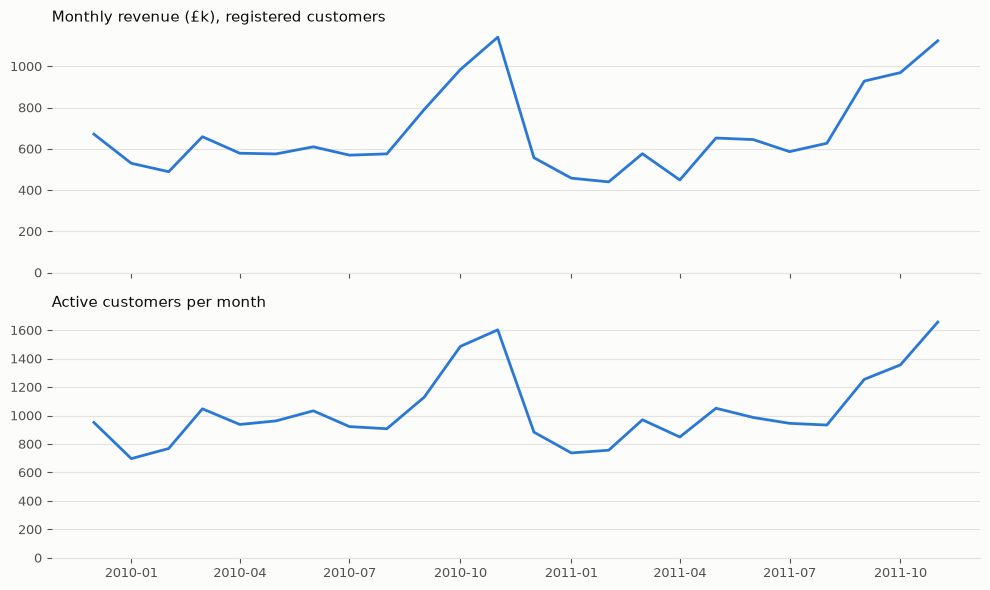

In [20]:
monthly = (purchases
           .set_index("invoice_date")
           .resample("MS")
           .agg({"revenue": "sum", "customer_id": "nunique"})
           .loc[:"2011-11"])

SERIES, TEXT, MUTED, GRID, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, facecolor=SURFACE)
panels = [("revenue", "Monthly revenue (£k), registered customers", 1e3),
          ("customer_id", "Active customers per month", 1)]

for ax, (col, title, scale) in zip(axes, panels):
    ax.set_facecolor(SURFACE)
    ax.plot(monthly.index, monthly[col] / scale, color=SERIES, linewidth=2)
    ax.set_title(title, loc="left", color=TEXT, fontsize=11)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.set_ylim(bottom=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_monthly_activity.png", dpi=150, facecolor=SURFACE)
plt.show()

## Save the outputs

In [21]:
columns = ["invoice", "invoice_date", "customer_id", "country",
           "stock_code", "description", "quantity", "price", "revenue"]

purchases[columns].sort_values("invoice_date").to_parquet(PROCESSED_DIR / "transactions.parquet", index=False)
returns[columns].sort_values("invoice_date").to_parquet(PROCESSED_DIR / "returns.parquet", index=False)
cleaning_log.to_csv(PROCESSED_DIR / "cleaning_log.csv")

print(f"Saved {len(purchases):,} purchase lines and {len(returns):,} return lines to {PROCESSED_DIR.name}/")

Saved 770,573 purchase lines and 11,564 return lines to processed/


## Summary of decisions

| Step | Decision | Reason |
|---|---|---|
| Sheet overlap | Keep 2010-12-01 → 09 from the first sheet only | Verified identical double export |
| Exact duplicates | Drop | Most likely double entries (assumption, ~1% of rows) |
| Missing customer ID | Drop | Customer-level analysis; IDs missing per whole invoice, cannot be imputed |
| Price ≤ 0 | Drop | Free items and accounting entries, not spending behaviour |
| Non-product codes | Drop | Postage, fees, adjustments and vouchers distort product spending |
| Returns | Pair with the cancelled purchase and remove both; keep the rest separately | Cancelled orders should not count as transactions in frequency and order value |
| Large orders | Keep | Real wholesale behaviour; handled later with log transforms / robust scaling |

**What this means downstream:** the analysis covers registered customers only (about 85% of revenue);
frequency will be counted on purchase invoices; the unpaired returns will be used to compute net
spend and a return-rate feature for churn.